# Data assimilation

## 0. Imports & Setup

In [1]:
import os
import glob
import re

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [2]:
# Detect HPC vs local
HOME = os.path.expanduser("~")
HPC_ROOT = os.path.join(HOME, "irp-efs25")
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))

# Use HPC path if it exists, otherwise local
IS_HPC = os.path.exists(HPC_ROOT)
ROOT = HPC_ROOT if IS_HPC else REPO_ROOT

# for SOCAT
START_DATE = "1993-01-01"
END_DATE = "2024-12-31"

# 5 ResNet members expected
EXPECTED_MEMBERS = {0: 42, 1: 43, 2: 44, 3: 45, 4: 46}

# 20% of valid SOCAT to withhold
HOLDOUT_FRACTION = 0.20
HOLDOUT_SEED = 42

# Fixed representativeness uncertainty added to each SOCAT observation
REPRESENTATIVENESS_ERROR = 5.0  # microatm

# Date used for four-panel map
PLOT_TIME = np.datetime64("2003-03-01")

# Derived paths
DATA_ROOT           = os.path.join(ROOT, "data")
PROCESSED_DATA_DIR  = os.path.join(DATA_ROOT, "processed")
SOCAT_LOAD_DIR      = os.path.join(PROCESSED_DATA_DIR, "socat")
SOCAT_LOAD_PATH     = os.path.join(SOCAT_LOAD_DIR, "SOCATv2026_gridded_monthly.zarr")
PREDICTIONS_DIR     = os.path.join(DATA_ROOT, "predictions")
PRIOR_LOAD_DIR      = os.path.join(PREDICTIONS_DIR, "prior", "ensemble_members")
PRIOR_LOAD_PATTERN  = os.path.join(PRIOR_LOAD_DIR, "resnet_satellite_pco2_member*_seed*.zarr")
POSTERIOR_SAVE_DIR  = os.path.join(PREDICTIONS_DIR, "posterior")
POSTERIOR_SAVE_PATH = os.path.join(POSTERIOR_SAVE_DIR, "assimilated_pco2_1993_2024.zarr")
POSTERIOR_DIAG_PATH = os.path.join(POSTERIOR_SAVE_DIR, "posterior_diagnostics.zarr")
FIGURES_DIR         = os.path.join(ROOT, "figures", "data_assimilation")

assert os.path.exists(SOCAT_LOAD_PATH), f"SOCAT dataset not found at {SOCAT_LOAD_PATH}"
assert os.path.exists(PRIOR_LOAD_DIR), f"Ensemble prior predictions dir not found at {PRIOR_LOAD_DIR}"

# create write dirs if don't exist
for dir_paths in [FIGURES_DIR, POSTERIOR_SAVE_DIR]:
    if not os.path.exists(dir_paths):
        os.makedirs(dir_paths, exist_ok=True)

print(f"Running on: {'HPC' if IS_HPC else 'local'}")
print(f"Root:                       {ROOT}")
print(f"Data root:                  {DATA_ROOT}")
print(f"SOCAT load:                 {SOCAT_LOAD_PATH}")
print(f"Prior predictions load:     {PRIOR_LOAD_DIR}")
print(f"Posterior predictions save: {POSTERIOR_SAVE_PATH}")
print(f"Figures:                    {FIGURES_DIR}")

Running on: HPC
Root:                       /rds/general/user/efs25/home/irp-efs25
Data root:                  /rds/general/user/efs25/home/irp-efs25/data
SOCAT load:                 /rds/general/user/efs25/home/irp-efs25/data/processed/socat/SOCATv2026_gridded_monthly.zarr
Prior predictions load:     /rds/general/user/efs25/home/irp-efs25/data/predictions/prior/ensemble_members
Posterior predictions save: /rds/general/user/efs25/home/irp-efs25/data/predictions/posterior/assimilated_pco2_1993_2024.zarr
Figures:                    /rds/general/user/efs25/home/irp-efs25/figures/data_assimilation


## 1. Load Zarrs

### Load 5 ResNet ensemble members

In [3]:
def find_ensemble_members(prior_dir, expected_members):
    """Find and validate the five saved ResNet ensemble-member Zarr stores"""

    pattern = os.path.join(prior_dir, "resnet_satellite_pco2_member*_seed*.zarr")

    records = []
    regex = re.compile(r"resnet_satellite_pco2_member(?P<member>\d+)_seed(?P<seed>\d+)\.zarr")

    for path in sorted(glob.glob(pattern)):
        match = regex.fullmatch(os.path.basename(path))
        if match is None:
            continue

        records.append({
            "path": path,
            "member": int(match.group("member")),
            "seed": int(match.group("seed")),
        })

    records = sorted(records, key=lambda x: x["member"])

    found = {r["member"]: r["seed"] for r in records}

    if found != expected_members:
        raise ValueError(f"Expected exactly the five ResNet members {expected_members} but found {found}")

    return records


member_records = find_ensemble_members(PRIOR_LOAD_DIR, EXPECTED_MEMBERS)

for record in member_records:
    print( f"Member {record['member']} | seed {record['seed']} | {record['path']}")

Member 0 | seed 42 | /rds/general/user/efs25/home/irp-efs25/data/predictions/prior/ensemble_members/resnet_satellite_pco2_member0_seed42.zarr
Member 1 | seed 43 | /rds/general/user/efs25/home/irp-efs25/data/predictions/prior/ensemble_members/resnet_satellite_pco2_member1_seed43.zarr
Member 2 | seed 44 | /rds/general/user/efs25/home/irp-efs25/data/predictions/prior/ensemble_members/resnet_satellite_pco2_member2_seed44.zarr
Member 3 | seed 45 | /rds/general/user/efs25/home/irp-efs25/data/predictions/prior/ensemble_members/resnet_satellite_pco2_member3_seed45.zarr
Member 4 | seed 46 | /rds/general/user/efs25/home/irp-efs25/data/predictions/prior/ensemble_members/resnet_satellite_pco2_member4_seed46.zarr


In [4]:
def load_prior_ensemble(member_records):
    """
    Load the five total-pCO2 prior fields and combine 
    them along 'member' dimension.
    """

    datasets = []

    for record in member_records:
        ds = xr.open_zarr(record["path"], consolidated=True)

        if "pco2_total_pred" not in ds:
            raise KeyError(f"{record['path']} does not contain 'pco2_total_pred'")

        # Some saved stores may contain a singleton member dimension.
        if "member" in ds.dims:
            if ds.sizes["member"] != 1:
                raise ValueError(
                    f"{record['path']} contains multiple members."
                )
            ds = ds.isel(member=0, drop=True)

        ds = ds.expand_dims(member=[record["member"]])
        datasets.append(ds)

    # Exact coordinate matching
    combined = xr.concat(
        datasets,
        dim="member",
        join="exact",
        compat="equals",
    ).sortby("member")

    return combined


ds_prior = load_prior_ensemble(member_records)

print("Prior dimensions:", dict(ds_prior.sizes))
print("Variables:", list(ds_prior.data_vars))
print("Members:", ds_prior.member.values)

assert ds_prior.sizes["member"] == 5
assert ds_prior["pco2_total_pred"].dims == ("member", "time", "lat", "lon")

Prior dimensions: {'member': 5, 'time': 384, 'lat': 180, 'lon': 360}
Variables: ['land_mask', 'pco2_baseline', 'pco2_nonthermal_pred', 'pco2_total_pred']
Members: [0 1 2 3 4]


### Load and align SOCAT observations

In [5]:
def align_monthly_data(ds_prior, ds_socat):
    """
    Align the prediction and SOCAT datasets using an explicit YYYYMM key
    SOCAT is middle month, prediction is start of month.
    """

    def add_month_key(ds):
        key = (ds.time.dt.year * 100 + ds.time.dt.month).astype(np.int32)
        return ds.assign_coords(month_key=("time", key.values))

    prior = add_month_key(ds_prior)
    socat = add_month_key(ds_socat)

    prior = prior.sel(time=slice(START_DATE, END_DATE))
    socat = socat.sel(time=slice(START_DATE, END_DATE))

    common = np.intersect1d(
        prior.month_key.values,
        socat.month_key.values,
    )

    if len(common) == 0:
        raise ValueError("No common months between prior and SOCAT.")

    prior = prior.isel(time=np.isin(prior.month_key, common))
    socat = socat.isel(time=np.isin(socat.month_key, common))

    prior = prior.isel(time=np.argsort(prior.month_key.values))
    socat = socat.isel(time=np.argsort(socat.month_key.values))

    common = np.sort(common)
    common_time = np.array(
        [
            np.datetime64(f"{month // 100:04d}-{month % 100:02d}-01", "ns")
            for month in common
        ]
    )

    prior = prior.assign_coords(time=("time", common_time))
    socat = socat.assign_coords(time=("time", common_time))

    if not np.array_equal(prior.time.values, socat.time.values):
        raise ValueError("Prior and SOCAT times are not aligned")

    return prior, socat


ds_socat_raw = xr.open_zarr(SOCAT_LOAD_PATH, consolidated=True)

ds_prior, ds_socat = align_monthly_data(ds_prior, ds_socat_raw)

print("Aligned period:", ds_prior.time.values[0], "to", ds_prior.time.values[-1])
print("Prior:", dict(ds_prior.sizes))
print("SOCAT:", dict(ds_socat.sizes))

Aligned period: 1993-01-01T00:00:00.000000000 to 2024-12-01T00:00:00.000000000
Prior: {'member': 5, 'time': 384, 'lat': 180, 'lon': 360}
SOCAT: {'time': 384, 'lat': 180, 'lon': 360, 'bnds': 2}


## 2. Preprocessing

### Build ocean and observation masks

In [6]:
def build_masks(ds_prior, ds_socat):
    """Return a common ocean mask and the valid SOCAT observation mask """

    land_mask = ds_prior["land_mask"]

    # in case land stored with member dimension
    if "member" in land_mask.dims:
        reference = land_mask.isel(member=0)

        for member in ds_prior.member.values[1:]:
            if not np.array_equal(
                reference.values,
                land_mask.sel(member=member).values,
            ):
                raise ValueError("Land masks differ between members.")

        ocean_mask = reference == 0
    else:
        ocean_mask = land_mask == 0

    # find cells containing observations
    observation_mask = ds_socat["fco2_count_nobs"] > 0

    valid_observation_mask = observation_mask & ocean_mask

    return ocean_mask.astype(bool), valid_observation_mask.astype(bool)


ocean_mask, observation_mask = build_masks(ds_prior, ds_socat)

print("Valid ocean cells:", int(ocean_mask.sum()))
print("Valid SOCAT cell/month observations:", int(observation_mask.sum()))

Valid ocean cells: 13177631


Valid SOCAT cell/month observations: 340367


### Create withheld SOCAT validation set

A fixed random 20% of valid SOCAT observations are witheld from assimilation. 

In [7]:
def split_observations(observation_mask, holdout_fraction=0.20, seed=42):
    """Randomly split valid SOCAT cell/month observations into 
    assimilation and withheld masks using a reproducible random seed
    """
    rng = np.random.default_rng(seed)

    valid_indices = np.argwhere(observation_mask.values)
    n_holdout = int(len(valid_indices) * holdout_fraction)

    chosen = rng.choice(
        len(valid_indices),
        size=n_holdout,
        replace=False,
    )

    holdout_indices = valid_indices[chosen]

    assimilation_mask = observation_mask.copy()
    holdout_mask = xr.zeros_like(observation_mask, dtype=bool)

    assimilation_values = assimilation_mask.values
    holdout_values = holdout_mask.values

    for t, lat, lon in holdout_indices:
        assimilation_values[t, lat, lon] = False
        holdout_values[t, lat, lon] = True

    assimilation_mask.values = assimilation_values
    holdout_mask.values = holdout_values

    return assimilation_mask, holdout_mask


assimilation_mask, holdout_mask = split_observations(
    observation_mask,
    holdout_fraction=HOLDOUT_FRACTION,
    seed=HOLDOUT_SEED,
)

print("Assimilated observations:", int(assimilation_mask.sum()))
print("Withheld observations:", int(holdout_mask.sum()))

Assimilated observations: 272294
Withheld observations: 68073


## 2. Ensemble Kalman Assimilation

In [ ]:
def ensemble_update(background_ensemble, observations, assimilation_mask, observation_std, observation_count, representativeness_error):
    """
    Assimilate one monthly observation field into a five-member ensemble

    Parameters
    ----------
    background_ensemble : ndarray
        Shape (n_members, n_grid)
    observations : ndarray
        Flattened observed pCO2 field, shape (n_grid,)
    assimilation_mask : ndarray
        Boolean mask selecting observations that are allowed into the update
    observation_std : ndarray
        SOCAT within-cell standard deviation.
    observation_count : ndarray
        Number of observations contributing to each cell
    representativeness_error : float
        Additional observation representativeness uncertainty in uatm

    Returns
    -------
    analysis_ensemble : ndarray
        Updated ensemble, shape (n_members, n_grid)
    """

    n_members, n_grid = background_ensemble.shape

    # A grid cell can only be updated if every ensemble member has a finite background value
    state_valid = np.all(np.isfinite(background_ensemble), axis=0)

    observation_variance = (
        (observation_std ** 2) / observation_count
        + representativeness_error ** 2
    )

    obs_indices = np.where(
        assimilation_mask
        & state_valid
        & np.isfinite(observations)
        & np.isfinite(observation_variance)
        & (observation_variance > 0)
    )[0]

    # No usable observations for this month: leave ensemble unchanged
    if len(obs_indices) == 0:
        return background_ensemble.copy()

    xb = background_ensemble
    xb_mean = xb.mean(axis=0)
    xb_anom = xb - xb_mean[None, :]

    # Ensemble values at the observation locations
    yb = xb[:, obs_indices]
    yb_mean = yb.mean(axis=0)
    yb_anom = yb - yb_mean[None, :]

    y = observations[obs_indices].astype(np.float64)
    r_diag = observation_variance[obs_indices].astype(np.float64)

    denominator = n_members - 1

    # Cross-covariance between the full state and observations:
    # Pb H^T, without explicitly constructing Pb.
    PbHt = (xb_anom.T @ yb_anom) / denominator

    # Observation-space background covariance:
    # H Pb H^T
    HPbHt = (yb_anom.T @ yb_anom) / denominator

    S = HPbHt + np.diag(r_diag)
    innovation = y - yb_mean

    # Solve S z = innovation rather than forming S^{-1}
    z = np.linalg.solve(S, innovation)

    analysis_mean = xb_mean + PbHt @ z

    # Deterministic square-root update for ensemble perturbations
    scaled_anomalies = yb_anom / np.sqrt(r_diag)[None, :]
    G = (scaled_anomalies @ scaled_anomalies.T) / denominator

    eigenvalues, eigenvectors = np.linalg.eigh(G)
    eigenvalues = np.maximum(eigenvalues, 0.0)

    transform = (
        eigenvectors
        @ np.diag(1.0 / np.sqrt(1.0 + eigenvalues))
        @ eigenvectors.T
    )

    analysis_anomalies = transform @ xb_anom
    analysis = analysis_mean[None, :] + analysis_anomalies

    # Preserve cells that were invalid in the prior
    invalid = ~state_valid
    analysis[:, invalid] = xb[:, invalid]

    return analysis

In [9]:
def run_assimilation(ds_prior, ds_socat, assimilation_mask, representativeness_error):
    """
    Run the monthly ensemble-space assimilation and 
    return prior/posterior ensemble summaries
    """

    prior = ds_prior["pco2_total_pred"].values.astype(np.float64)

    n_members, n_time, n_lat, n_lon = prior.shape
    n_grid = n_lat * n_lon

    observations = ds_socat["pco2_ave_weighted"].values.astype(np.float64)
    observation_std = ds_socat["pco2_std_weighted"].values.astype(np.float64)
    observation_count = ds_socat["fco2_count_nobs"].values.astype(np.float64)

    prior_mean = np.full((n_time, n_lat, n_lon), np.nan)
    prior_std = np.full((n_time, n_lat, n_lon), np.nan)

    posterior_mean = np.full((n_time, n_lat, n_lon), np.nan)
    posterior_std = np.full((n_time, n_lat, n_lon), np.nan)

    for t in range(n_time):
        # State vector for this month: (5 members, 180*360 grid cells)
        xb = prior[:, t].reshape(n_members, n_grid)

        xa = ensemble_update(
            background_ensemble=xb,
            observations=observations[t].reshape(-1),
            assimilation_mask=assimilation_mask.isel(time=t).values.reshape(-1),
            observation_std=observation_std[t].reshape(-1),
            observation_count=observation_count[t].reshape(-1),
            representativeness_error=representativeness_error,
        )

        xb_field = xb.reshape(n_members, n_lat, n_lon)
        xa_field = xa.reshape(n_members, n_lat, n_lon)

        # Ensemble mean and sample standard deviation (ddof=1).
        prior_mean[t] = np.nanmean(xb_field, axis=0)
        prior_std[t] = np.nanstd(xb_field, axis=0, ddof=1)

        posterior_mean[t] = np.nanmean(xa_field, axis=0)
        posterior_std[t] = np.nanstd(xa_field, axis=0, ddof=1)

        if (t + 1) % 24 == 0:
            print(f"Assimilated {t + 1}/{n_time} months")

    coords = {
        "time": ds_prior.time.values,
        "lat": ds_prior.lat.values,
        "lon": ds_prior.lon.values,
    }

    return (
        xr.DataArray(
            prior_mean,
            dims=("time", "lat", "lon"),
            coords=coords,
            name="pco2_background_mean",
        ),
        xr.DataArray(
            prior_std,
            dims=("time", "lat", "lon"),
            coords=coords,
            name="pco2_background_uncertainty",
        ),
        xr.DataArray(
            posterior_mean,
            dims=("time", "lat", "lon"),
            coords=coords,
            name="pco2_analysis_mean",
        ),
        xr.DataArray(
            posterior_std,
            dims=("time", "lat", "lon"),
            coords=coords,
            name="pco2_analysis_uncertainty",
        ),
    )


background_mean, background_std, posterior_mean, posterior_std = run_assimilation(ds_prior, ds_socat, assimilation_mask, REPRESENTATIVENESS_ERROR)

print("Assimilation complete.")
print("Posterior shape:", posterior_mean.shape)

/var/tmp/pbs.3934554.pbs-7/ipykernel_680114/1127962377.py:39: RuntimeWarning: Mean of empty slice
  prior_mean[t] = np.nanmean(xb_field, axis=0)
/rds/general/user/efs25/home/miniconda3/envs/irp-efs25/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/var/tmp/pbs.3934554.pbs-7/ipykernel_680114/1127962377.py:42: RuntimeWarning: Mean of empty slice
  posterior_mean[t] = np.nanmean(xa_field, axis=0)


Assimilated 24/384 months


Assimilated 48/384 months


Assimilated 72/384 months


Assimilated 96/384 months


...

Assimilated 288/384 months


Assimilated 312/384 months


Assimilated 336/384 months


Assimilated 360/384 months


Assimilated 384/384 months
Assimilation complete.
Posterior shape: (384, 180, 360)


## 3. Evaluation

In [10]:
def regression_metrics(prediction, observations, mask):
    """Calculate MAE, RMSE, bias, correlation and sample count"""

    pred = prediction.where(mask).values.ravel()
    obs = observations.where(mask).values.ravel()

    valid = np.isfinite(pred) & np.isfinite(obs)
    pred = pred[valid]
    obs = obs[valid]

    return {
        "N": len(pred),
        "MAE": float(np.mean(np.abs(pred - obs))),
        "RMSE": float(np.sqrt(np.mean((pred - obs) ** 2))),
        "Bias": float(np.mean(pred - obs)),
        "Correlation": float(np.corrcoef(obs, pred)[0, 1]),
    }


prior_holdout_metrics = regression_metrics(
    background_mean, 
    ds_socat["pco2_ave_weighted"],
    holdout_mask,
)

posterior_holdout_metrics = regression_metrics(
    posterior_mean,
    ds_socat["pco2_ave_weighted"],
    holdout_mask,
)

print("Prior:", prior_holdout_metrics)
print("Posterior:", posterior_holdout_metrics)

Prior: {'N': 68073, 'MAE': 17.7865851959194, 'RMSE': 28.305745470543606, 'Bias': -3.0766103300159746, 'Correlation': 0.7698371569032142}
Posterior: {'N': 68073, 'MAE': 17.125127099293564, 'RMSE': 27.021650248055046, 'Bias': -2.5374649989603344, 'Correlation': 0.7918585651513941}


In [11]:
def metric_improvement(prior_metrics, posterior_metrics):
    """Calculate absolute and percentage improvement in MAE and RMSE"""

    return {
        "MAE_reduction": prior_metrics["MAE"] - posterior_metrics["MAE"],
        "MAE_improvement_percent": 100 * (prior_metrics["MAE"] - posterior_metrics["MAE"]) / prior_metrics["MAE"],
        "RMSE_reduction": prior_metrics["RMSE"] - posterior_metrics["RMSE"],
        "RMSE_improvement_percent": 100 * (prior_metrics["RMSE"] - posterior_metrics["RMSE"]) / prior_metrics["RMSE"]
    }


improvement = metric_improvement(
    prior_holdout_metrics,
    posterior_holdout_metrics,
)

print(improvement)

{'MAE_reduction': 0.6614580966258359, 'MAE_improvement_percent': 3.718859406343988, 'RMSE_reduction': 1.2840952224885598, 'RMSE_improvement_percent': 4.536517944121466}


Make table

In [12]:
evaluation_table = pd.DataFrame(
    {
        "Prior": [
            prior_holdout_metrics["MAE"],
            prior_holdout_metrics["RMSE"],
            prior_holdout_metrics["Bias"],
            prior_holdout_metrics["Correlation"],
        ],
        "Posterior": [
            posterior_holdout_metrics["MAE"],
            posterior_holdout_metrics["RMSE"],
            posterior_holdout_metrics["Bias"],
            posterior_holdout_metrics["Correlation"],
        ],
    },
    index=[
        "MAE (µatm)",
        "RMSE (µatm)",
        "Bias (µatm)",
        "Correlation",
    ],
)

evaluation_table

,Prior,Posterior
MAE (µatm),17.786585,17.125127
RMSE (µatm),28.305745,27.021650
Bias (µatm),-3.076610,-2.537465
Correlation,0.769837,0.791859


## 4. Visualisations

Total valid SOCAT: 538
Assimilated: 435


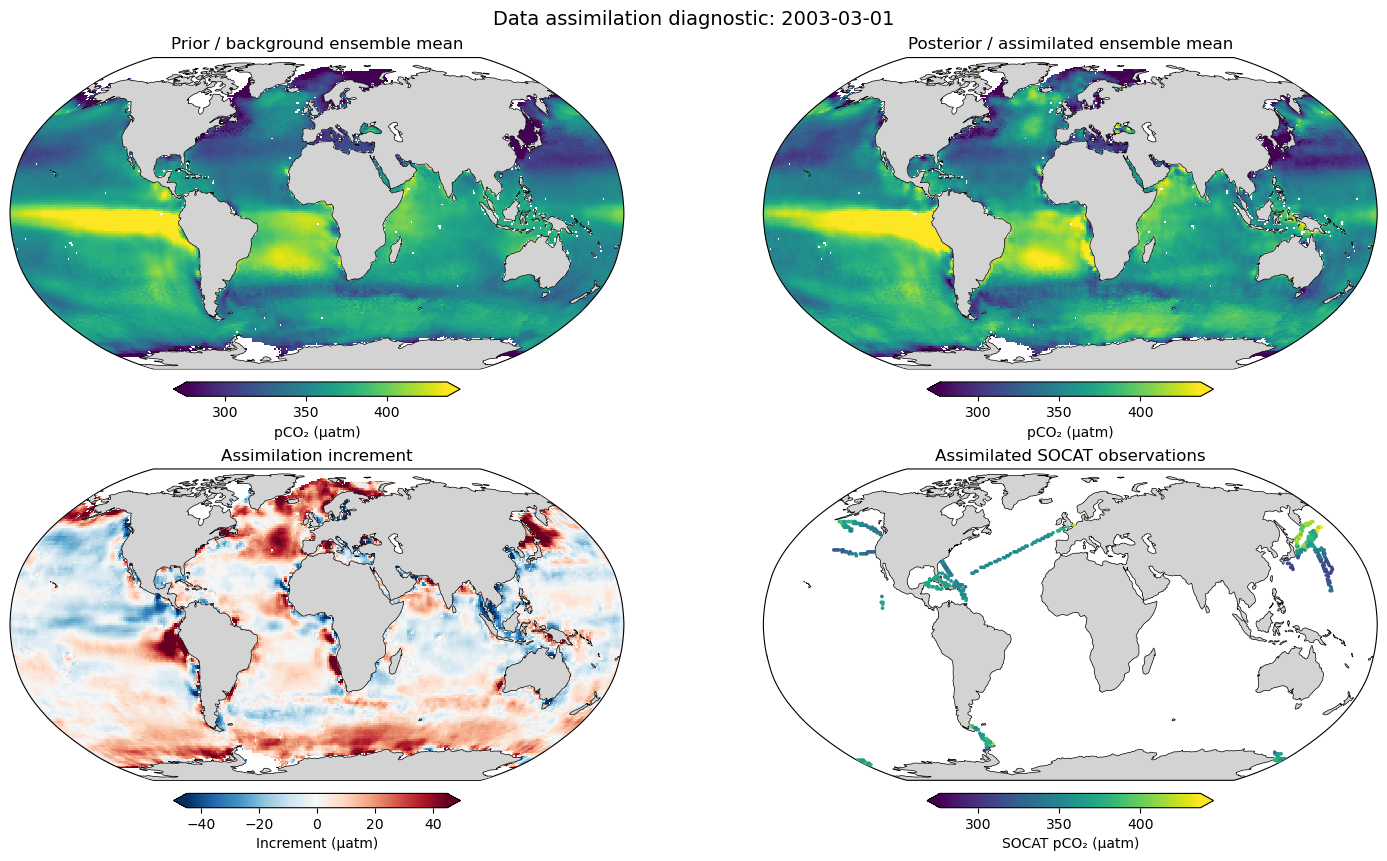

Saved: /rds/general/user/efs25/home/irp-efs25/figures/data_assimilation/data_assimilation_four_panel_cartopy.png


In [13]:
def plot_assimilation_four_panel(background, posterior, observations, assimilation_mask, time, save_path=None):
    """Create four panel global assimilation map"""

    background = background.sel(time=time)
    posterior = posterior.sel(time=time)
    observations = observations.sel(time=time)
    assimilation_mask = assimilation_mask.sel(time=time)

    increment = posterior - background

    # Use one common scale for prior, posterior and observations
    pco2_fields = np.concatenate([
        background.values[np.isfinite(background.values)],
        posterior.values[np.isfinite(posterior.values)],
        observations.values[np.isfinite(observations.values)],
    ])

    pco2_vmin, pco2_vmax = np.nanpercentile(
        pco2_fields, [2, 98]
    )

    # Increment is centred around zero
    increment_limit = np.nanpercentile(np.abs(increment.values[np.isfinite(increment.values)]), 98)
    increment_limit = max(increment_limit, 1.0)

    projection = ccrs.Robinson()
    data_crs = ccrs.PlateCarree()

    fig, axes = plt.subplots(2, 2, figsize=(15, 8.5), subplot_kw={"projection": projection}, constrained_layout=True)

    panels = [
        (
            background,
            "Prior / background ensemble mean",
            "viridis",
            pco2_vmin,
            pco2_vmax,
        ),
        (
            posterior,
            "Posterior / assimilated ensemble mean",
            "viridis",
            pco2_vmin,
            pco2_vmax,
        ),
        (
            increment,
            "Assimilation increment",
            "RdBu_r",
            -increment_limit,
            increment_limit,
        ),
    ]

    for ax, (field, title, cmap, vmin, vmax) in zip(axes.flat[:3], panels):
        mesh = ax.pcolormesh(
            field.lon,
            field.lat,
            field,
            transform=data_crs,
            shading="auto",
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            rasterized=True,
        )

        ax.add_feature(cfeature.LAND, facecolor="lightgray", edgecolor="none", zorder=3)
        ax.coastlines(linewidth=0.5, zorder=4)
        ax.set_global()
        ax.set_title(title)

        label = "pCO₂ (μatm)" if "increment" not in title.lower() else "Increment (μatm)"
        cbar = fig.colorbar(
            mesh,
            ax=ax,
            orientation="horizontal",
            fraction=0.046,
            pad=0.04,
            extend="both",
        )
        cbar.set_label(label)

    # Fourth panel: assimilated observations only
    ax = axes.flat[3]
    ax.set_global()
    ax.add_feature(
        cfeature.LAND,
        facecolor="lightgray",
        edgecolor="none",
        zorder=1,
    )
    ax.coastlines(linewidth=0.5, zorder=2)

    obs_valid = np.isfinite(observations.values)
    assim_locations = assimilation_mask.values & obs_valid

    lon2d, lat2d = np.meshgrid(
        observations.lon.values,
        observations.lat.values,
    )

    print("Total valid SOCAT:", obs_valid.sum())
    print("Assimilated:", assim_locations.sum())

    # Plot assimilated SOCAT observations
    sc_assim = ax.scatter(
        lon2d[assim_locations],
        lat2d[assim_locations],
        c=observations.values[assim_locations],
        cmap="viridis",
        vmin=pco2_vmin,
        vmax=pco2_vmax,
        s=7,
        marker="o",
        transform=data_crs,
        zorder=4,
        linewidths=0,
    )

    ax.set_title("Assimilated SOCAT observations")

    cbar = fig.colorbar(
        sc_assim,
        ax=ax,
        orientation="horizontal",
        fraction=0.046,
        pad=0.04,
        extend="both",
    )
    cbar.set_label("SOCAT pCO₂ (μatm)")

    fig.suptitle(
        f"Data assimilation diagnostic: {str(time)[:10]}",
        fontsize=14,
    )

    if save_path is not None:
        fig.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
        )

    return fig


figure_path = os.path.join(FIGURES_DIR, "data_assimilation_four_panel_cartopy.png")

fig = plot_assimilation_four_panel(
    background=background_mean,
    posterior=posterior_mean,
    observations=ds_socat["pco2_ave_weighted"],
    assimilation_mask=assimilation_mask,
    time=PLOT_TIME,
    save_path=figure_path,
)

plt.show()

print("Saved:", figure_path)

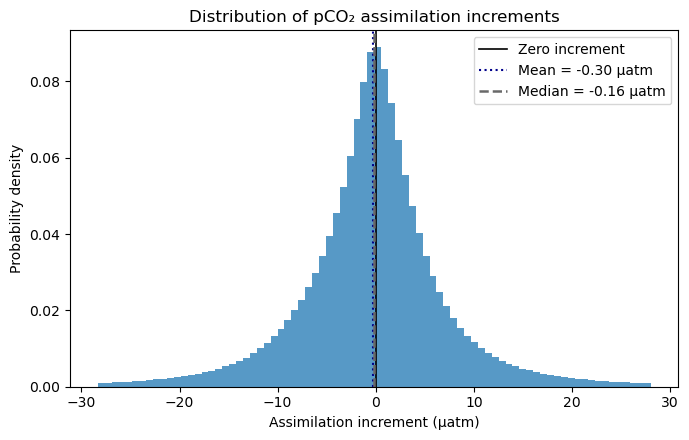

In [14]:
def plot_increment_distribution(increment_values, plot_values):
    mean_increment = np.mean(increment_values)
    median_increment = np.median(increment_values)

    fig, ax = plt.subplots(figsize=(7, 4.5))

    ax.hist(
        plot_values,
        bins=80,
        density=True,
        alpha=0.75,
    )

    ax.axvline(
        0,
        color="black",
        linestyle="-",
        linewidth=1.2,
        label="Zero increment",
    )

    ax.axvline(
        mean_increment,
        color="darkblue",
        linestyle=":",
        linewidth=1.5,
        label=f"Mean = {mean_increment:.2f} μatm",
    )

    ax.axvline(
        median_increment,
        color="dimgrey",
        linestyle="--",
        linewidth=1.8,
        label=f"Median = {median_increment:.2f} μatm",
    )

    ax.set_xlabel("Assimilation increment (μatm)")
    ax.set_ylabel("Probability density")
    ax.set_title("Distribution of pCO₂ assimilation increments")
    ax.legend()

    plt.tight_layout()
    plt.show()


increments = (posterior_mean - background_mean).values

valid = np.isfinite(increments)
increment_values = increments[valid]

p1, p99 = np.percentile(increment_values, [1, 99])
plot_values = increment_values[(increment_values >= p1) & (increment_values <= p99)]

plot_increment_distribution(increment_values, plot_values)

### Prior vs posterior against withheld SOCAT

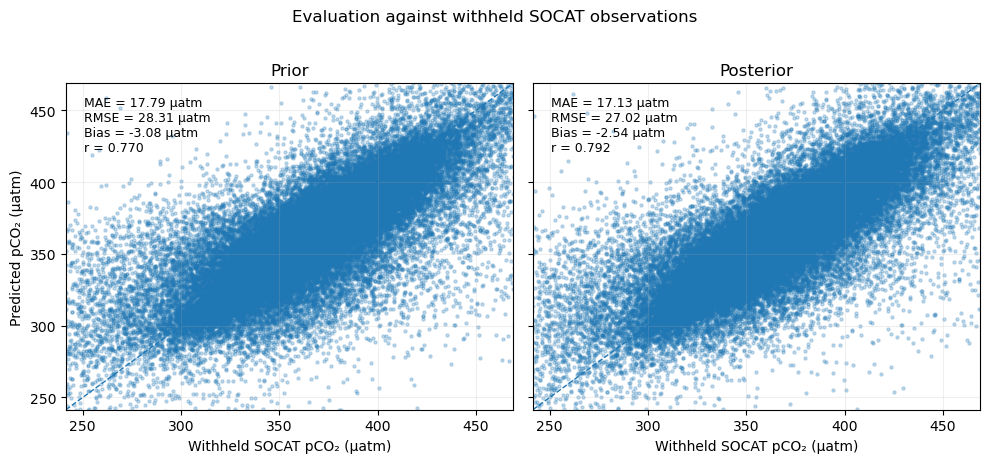

In [15]:
def plot_prior_posterior_scatter(background_mean, posterior_mean, observations, holdout_mask, save_path=None):
    """
    Compare prior and posterior pCO2 against withheld SOCAT observations

    Only withheld observations are used, so neither panel evaluates against
    observations that were supplied to the assimilation
    """

    prior = background_mean.where(holdout_mask).values.ravel()
    posterior = posterior_mean.where(holdout_mask).values.ravel()
    obs = observations.where(holdout_mask).values.ravel()

    valid = np.isfinite(prior) & np.isfinite(posterior) & np.isfinite(obs)

    prior = prior[valid]
    posterior = posterior[valid]
    obs = obs[valid]

    # Use the same limits for both panels
    all_values = np.concatenate([obs, prior, posterior])
    vmin, vmax = np.nanpercentile(all_values, [1, 99])

    # Add small margin around the data range
    margin = 0.03 * (vmax - vmin)
    vmin -= margin
    vmax += margin

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(10, 4.5),
        sharex=True,
        sharey=True,
    )

    panels = [(axes[0], prior, "Prior"), (axes[1], posterior, "Posterior")]

    for ax, prediction, title in panels:

        ax.scatter(
            obs,
            prediction,
            s=5,
            alpha=0.25,
            rasterized=True,
        )

        # 1:1 line
        ax.plot(
            [vmin, vmax],
            [vmin, vmax],
            linestyle="--",
            linewidth=1,
        )

        # Calculate metrics for this panel
        error = prediction - obs

        mae = np.mean(np.abs(error))
        rmse = np.sqrt(np.mean(error**2))
        bias = np.mean(error)
        corr = np.corrcoef(obs, prediction)[0, 1]

        ax.text(
            0.04,
            0.96,
            f"MAE = {mae:.2f} µatm\n"
            f"RMSE = {rmse:.2f} µatm\n"
            f"Bias = {bias:.2f} µatm\n"
            f"r = {corr:.3f}",
            transform=ax.transAxes,
            va="top",
            fontsize=9,
        )

        ax.set_title(title)
        ax.set_xlim(vmin, vmax)
        ax.set_ylim(vmin, vmax)
        ax.grid(alpha=0.2)

    axes[0].set_ylabel("Predicted pCO₂ (μatm)")
    axes[0].set_xlabel("Withheld SOCAT pCO₂ (μatm)")

    axes[1].set_xlabel("Withheld SOCAT pCO₂ (μatm)")

    fig.suptitle("Evaluation against withheld SOCAT observations", y=1.02)

    plt.tight_layout()

    if save_path is not None:
        fig.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
        )

    return fig

scatter_path = os.path.join(FIGURES_DIR, "data_assimilation_prior_posterior_scatter.png")

fig = plot_prior_posterior_scatter(
    background_mean=background_mean,
    posterior_mean=posterior_mean,
    observations=ds_socat["pco2_ave_weighted"],
    holdout_mask=holdout_mask,
    save_path=scatter_path,
)

plt.show()

### Error improvement spatial map

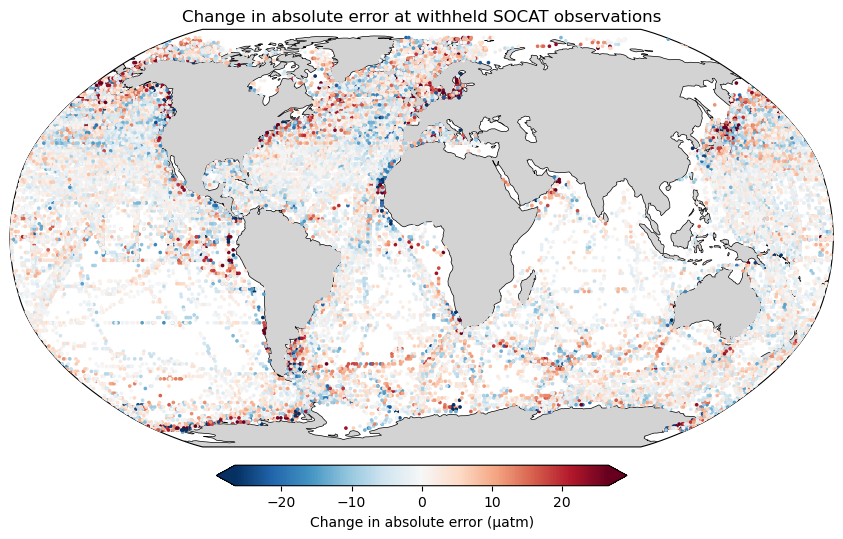

In [16]:
def plot_error_improvement_map(background_mean, posterior_mean, observations, save_path=None):
    """
    Plot the change in absolute error at withheld SOCAT observations.

    Positive values indicate that assimilation reduced the absolute error;
    negative values indicate that the posterior was less accurate than
    the prior at that withheld observation.
    """

    prior = background_mean.where(holdout_mask)
    posterior = posterior_mean.where(holdout_mask)
    obs = observations.where(holdout_mask)

    prior_error = np.abs(prior-obs)
    posterior_error = np.abs(posterior-obs)

    improvement = prior_error - posterior_error

    values = improvement.values
    valid = np.isfinite(values)

    # Symmetric colour scale around zero
    limit = np.nanpercentile(np.abs(values[valid]), 98)

    fig = plt.figure(figsize=(10, 5.5))

    ax = plt.axes(projection=ccrs.Robinson())
    ax.set_global()
    ax.add_feature(cfeature.LAND, facecolor="lightgray", edgecolor="none", zorder=1)
    ax.coastlines(linewidth=0.5, zorder=2)

    lon2d, lat2d = np.meshgrid(improvement.lon.values, improvement.lat.values)

    # Repeat coordinates for every month
    lon = np.broadcast_to(lon2d, improvement.shape)
    lat = np.broadcast_to(lat2d, improvement.shape)

    scatter = ax.scatter(
        lon[valid],
        lat[valid],
        c=values[valid],
        cmap="RdBu_r",
        vmin=-limit,
        vmax=limit,
        s=7,
        transform=ccrs.PlateCarree(),
        rasterized=True,
        zorder=3,
        linewidths=0,
    )
    cbar = fig.colorbar(
        scatter,
        ax=ax,
        orientation="horizontal",
        fraction=0.045,
        pad=0.04,
        extend="both",
    )
    cbar.set_label("Change in absolute error (μatm)")
    ax.set_title("Change in absolute error at withheld SOCAT observations")
    plt.tight_layout()

    if save_path is not None:
        fig.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
        )

    return fig
    
error_map_path = os.path.join(FIGURES_DIR, "data_assimilation_error_improvement.png")

fig = plot_error_improvement_map(
    background_mean=background_mean,
    posterior_mean=posterior_mean,
    observations=ds_socat["pco2_ave_weighted"],
    save_path=error_map_path
)

plt.show()

## 5. Save posterior

In [17]:
land_mask = xr.where(ocean_mask, 0, 1).astype(np.int8)
land_mask.name = "land_mask"

posterior_ds = xr.Dataset(
    {
        "pco2_total": posterior_mean.astype(np.float32),
        "pco2_uncertainty": posterior_std.astype(np.float32),
        "land_mask": land_mask,
    }
)

posterior_ds["pco2_total"].attrs.update({
    "long_name": "Assimilated monthly surface-ocean total pCO2",
    "units": "uatm",
})

posterior_ds["pco2_uncertainty"].attrs.update({
    "long_name": "Posterior ensemble standard deviation",
    "units": "uatm",
})

posterior_ds.attrs.update({
    "title": "Assimilated monthly surface-ocean pCO2 product",
    "period": f"{str(ds_prior.time.values[0])[:10]} to {str(ds_prior.time.values[-1])[:10]}",
    "method": "Ensemble-space deterministic square-root Kalman update",
    "n_members_used": 5,
    "member_ids_used": [int(x) for x in ds_prior.member.values],
    "member_seeds": [EXPECTED_MEMBERS[int(x)] for x in ds_prior.member.values],
    "holdout_fraction": HOLDOUT_FRACTION,
    "holdout_seed": HOLDOUT_SEED,
    "representativeness_error_uatm": REPRESENTATIVENESS_ERROR,
})

posterior_ds.to_zarr(
    POSTERIOR_SAVE_PATH,
    mode="w",
    consolidated=True,
)

diagnostic_ds = xr.Dataset(
    {
        "pco2_background_mean": background_mean.astype(np.float32),
        "pco2_background_uncertainty": background_std.astype(np.float32),
        "pco2_analysis_increment": (
            posterior_mean - background_mean
        ).astype(np.float32),
        "assimilation_mask": assimilation_mask.astype(np.int8),
        "holdout_mask": holdout_mask.astype(np.int8),
    }
)

diagnostic_ds.to_zarr(
    POSTERIOR_DIAG_PATH,
    mode="w",
    consolidated=True,
)

print("Saved posterior:", POSTERIOR_SAVE_PATH)
print("Saved diagnostics:", POSTERIOR_DIAG_PATH)

Saved posterior: /rds/general/user/efs25/home/irp-efs25/data/predictions/posterior/assimilated_pco2_1993_2024.zarr
Saved diagnostics: /rds/general/user/efs25/home/irp-efs25/data/predictions/posterior/posterior_diagnostics.zarr


Check reopening and that all members were used

In [18]:
check = xr.open_zarr(POSTERIOR_SAVE_PATH, consolidated=True)

print(check)
print("Posterior variables:", list(check.data_vars))
print("Posterior dimensions:", dict(check.sizes))
print("Members used:", check.attrs["member_ids_used"])
print("Period:", check.attrs["period"])

assert check.sizes["time"] == ds_prior.sizes["time"]
assert check.sizes["lat"] == ds_prior.sizes["lat"]
assert check.sizes["lon"] == ds_prior.sizes["lon"]
assert check.attrs["n_members_used"] == 5

<xarray.Dataset> Size: 224MB
Dimensions:           (time: 384, lat: 180, lon: 360)
Coordinates:
  * time              (time) datetime64[ns] 3kB 1993-01-01 ... 2024-12-01
    month_key         (time) int32 2kB dask.array<chunksize=(384,), meta=np.ndarray>
  * lat               (lat) float64 1kB -89.5 -88.5 -87.5 ... 87.5 88.5 89.5
  * lon               (lon) float64 3kB -179.5 -178.5 -177.5 ... 178.5 179.5
    member            int64 8B ...
Data variables:
    land_mask         (time, lat, lon) int8 25MB dask.array<chunksize=(96, 45, 180), meta=np.ndarray>
    pco2_total        (time, lat, lon) float32 100MB dask.array<chunksize=(48, 45, 90), meta=np.ndarray>
    pco2_uncertainty  (time, lat, lon) float32 100MB dask.array<chunksize=(48, 45, 90), meta=np.ndarray>
Attributes:
    holdout_fraction:               0.2
    holdout_seed:                   42
    member_ids_used:                [0, 1, 2, 3, 4]
    member_seeds:                   [42, 43, 44, 45, 46]
    method:                 